In [237]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [238]:
all_data = pd.read_parquet('../FLHitting/hitter_agg.parquet', engine='pyarrow')

In [448]:
min_at_bats = 150 # Choose min BBE

HR/AB Model (2 Variables)

In [449]:
data = all_data[all_data['at_bats'] >= min_at_bats]

In [450]:
data.columns

Index(['Batter', 'BatterTeam', 'pitches_seen', 'swings', 'whiffs',
       'chase_swings', 'foul_balls', 'balls_in_play', 'called_strikes',
       'swinging_strikes', 'swing_rate', 'whiff_rate', 'chase_rate',
       'in_play_rate', 'contact_rate', 'zone_swings', 'zone_contact',
       'zone_contact_rate', 'avg_exit_velo', 'avg_launch_angle',
       'avg_direction', 'avg_batspeed', 'avg_xDamage', 'avg_xwOBA', 'avg_xSLG',
       'avg_xBA', 'plate_appearances', 'strikeouts', 'walks', 'strikeout_rate',
       'walk_rate', 'home_runs', 'at_bats', 'hr_per_ab', 'singles', 'doubles',
       'triples', 'hits', 'total_bases', 'iso', 'babip', 'obp', 'slg', 'ops',
       'pull_air_bbe', 'total_bbe', 'pull_air_pct', 'Year',
       'natural_attack_angle', 'natural_max_ev', 'natural_method'],
      dtype='object')

Binomial GLM (2 Variables)

In [451]:
data = data.rename(columns = {'at_bats' : 'AB',
                              'home_runs': 'HR',
                              'natural_max_ev' : 'Max_EV',
                              'natural_attack_angle' : 'Natural_Attack_Angle',
                              'pull_air_pct' : 'PullAirPct',
                              'hr_per_ab' : 'HR_AB'})

In [452]:
data["HR_fail"] = data["AB"] - data["HR"]
data['Max_EV_2'] = data['Max_EV']**2

In [453]:
X = data[['Natural_Attack_Angle', 'Max_EV', 'contact_rate', 'PullAirPct', 'babip']]
y = data['avg_xwOBA']

(array([ 1.,  3., 14., 37., 48., 37., 14.,  8.,  2.,  1.]),
 array([0.21837075, 0.24380493, 0.26923911, 0.2946733 , 0.32010748,
        0.34554166, 0.37097584, 0.39641003, 0.42184421, 0.44727839,
        0.47271257]),
 <BarContainer object of 10 artists>)

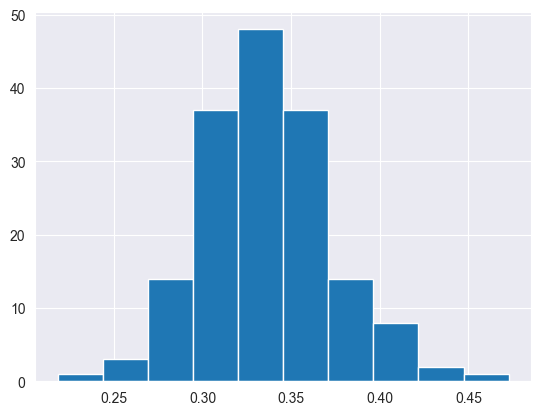

In [454]:
plt.hist(data['avg_xwOBA'])

In [455]:
from scipy.stats import shapiro

stat, p = shapiro(data["avg_xwOBA"])
print("Shapiro-Wilk test statistic:", stat)
print("p-value:", p)


Shapiro-Wilk test statistic: 0.9856265352116106
p-value: 0.08718387720765153


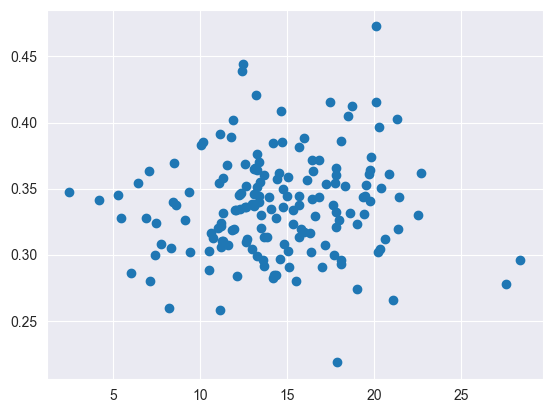

In [456]:
plt.scatter(data['Natural_Attack_Angle'], data['avg_xwOBA'])

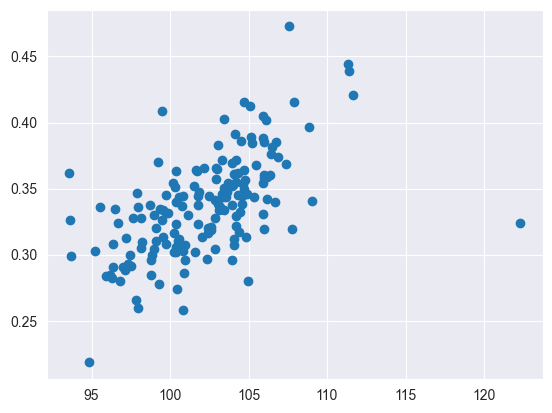

In [457]:
plt.scatter(data['Max_EV'], data['avg_xwOBA'])

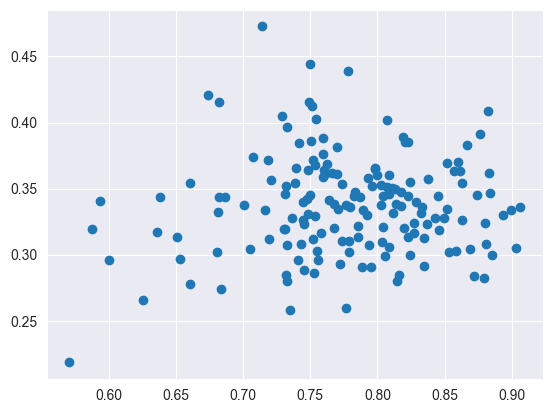

In [458]:
plt.scatter(data['contact_rate'], data['avg_xwOBA'])

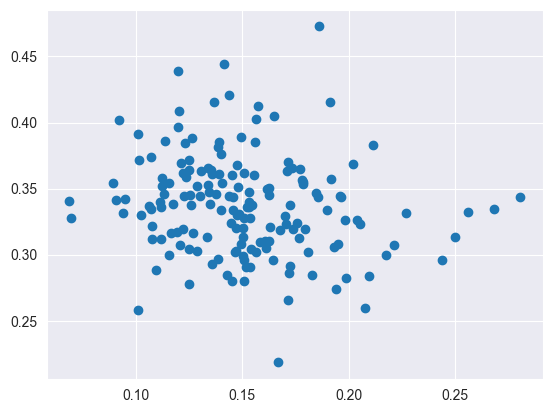

In [459]:
plt.scatter(data['PullAirPct'], data['avg_xwOBA'])

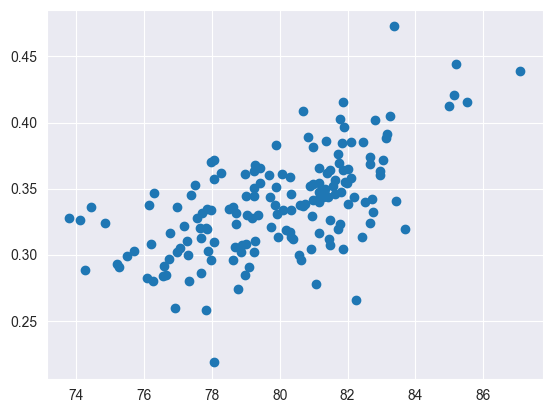

In [460]:
plt.scatter(data['avg_exit_velo'], data['avg_xwOBA'])

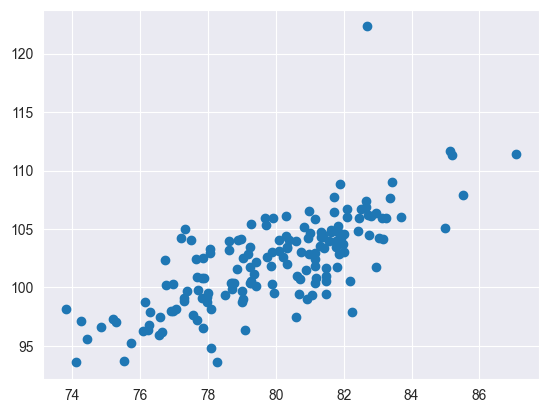

In [461]:
plt.scatter(data['avg_exit_velo'], data['Max_EV'])

In [546]:
np.corrcoef(data['avg_exit_velo'], data['Max_EV'])

array([[1.        , 0.73767548],
       [0.73767548, 1.        ]])

In [556]:
feature_names = ['Max_EV', 'contact_rate', 'Natural_Attack_Angle', 'PullAirPct', 'avg_exit_velo', 'babip']
dep_var = 'avg_xSLG'

In [557]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# ============================================================
# 1. Split indices (single source of truth)
# ============================================================
indices = np.arange(len(data))

train_idx, test_idx = train_test_split(
    indices, test_size=0.2, random_state=42
)

# ============================================================
# 2. Build X and y using those indices
# ============================================================
X = data[feature_names].to_numpy()
y = data[dep_var].to_numpy()

X_train = X[train_idx]
X_test  = X[test_idx]

y_train = y[train_idx]
y_test  = y[test_idx]

# ============================================================
# 3. Fit Random Forest
# ============================================================
rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

# ============================================================
# 4. Predictions + Residuals
# ============================================================
train_preds = rf.predict(X_train)
test_preds  = rf.predict(X_test)

train_residuals = y_train - train_preds
test_residuals  = y_test  - test_preds

# ============================================================
# 5. Team labels (use iloc because indices are positional)
# ============================================================
train_teams = data.iloc[train_idx]["BatterTeam"].reset_index(drop=True)
test_teams  = data.iloc[test_idx]["BatterTeam"].reset_index(drop=True)

# ============================================================
# 6. Train/Test residuals by team
# ============================================================
train_res_df = pd.DataFrame({
    "BatterTeam": train_teams,
    "residual": train_residuals
})

test_res_df = pd.DataFrame({
    "BatterTeam": test_teams,
    "residual": test_residuals
})

mean_train_residuals = (
    train_res_df.groupby("BatterTeam")["residual"]
    .mean()
    .sort_values()
)

mean_test_residuals = (
    test_res_df.groupby("BatterTeam")["residual"]
    .mean()
    .sort_values()
)

# ============================================================
# 7. Cross‑Validation residuals by team
# ============================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_fold_results = []
cv_r2_scores = []

for fold, (cv_train_rel, cv_val_rel) in enumerate(kf.split(train_idx)):

    # Convert fold-relative indices → absolute indices
    abs_train = train_idx[cv_train_rel]
    abs_val   = train_idx[cv_val_rel]

    # Build fold data
    X_tr = X[abs_train]
    X_va = X[abs_val]
    y_tr = y[abs_train]
    y_va = y[abs_val]

    # Fit fold model
    rf_fold = RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    )
    rf_fold.fit(X_tr, y_tr)

    # Predict + residuals
    val_preds = rf_fold.predict(X_va)
    val_residuals = y_va - val_preds

    # R² for this fold
    cv_r2_scores.append(r2_score(y_va, val_preds))

    # Team labels for this fold
    val_teams = data.iloc[abs_val]["BatterTeam"].reset_index(drop=True)

    fold_df = pd.DataFrame({
        "fold": fold,
        "BatterTeam": val_teams,
        "actual": y_va,
        "pred": val_preds,
        "residual": val_residuals
    })
    cv_fold_results.append(fold_df)


# Combine all folds
cv_res_df = pd.concat(cv_fold_results, ignore_index=True)

mean_cv_residuals = (
    cv_res_df.groupby("BatterTeam")["residual"]
    .mean()
    .sort_values()
)

# ============================================================
# 8. Outputs
# ============================================================
print("\n=== TEST SET R² SCORE ===")
print(r2_score(y_test, test_preds))


print("\n=== CROSS‑VALIDATION R² SCORES ===")
print(cv_r2_scores)
print("Mean CV R²:", np.mean(cv_r2_scores))




=== TEST SET R² SCORE ===
0.5758815648471471

=== CROSS‑VALIDATION R² SCORES ===
[0.545515074777841, 0.6628458877894454, 0.754941123417237, 0.6819575467344926, 0.5680901623239192]
Mean CV R²: 0.6426699590085871


In [558]:
# ============================================================
# Feature Importance
# ============================================================
feature_importances = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("\n=== FEATURE IMPORTANCE ===")
print(feature_importances)


=== FEATURE IMPORTANCE ===
Max_EV                  0.579226
avg_exit_velo           0.261467
babip                   0.053973
Natural_Attack_Angle    0.037418
contact_rate            0.036605
PullAirPct              0.031311
dtype: float64


In [559]:
print("Mean y_train:", y_train.mean())
print("Mean RF prediction:", train_preds.mean())
print("Min y_train:", y_train.min())
print("Min RF prediction:", train_preds.min())

Mean y_train: 0.41213332151869403
Mean RF prediction: 0.4126048059609046
Min y_train: 0.22559239130434774
Min RF prediction: 0.2566055222591762


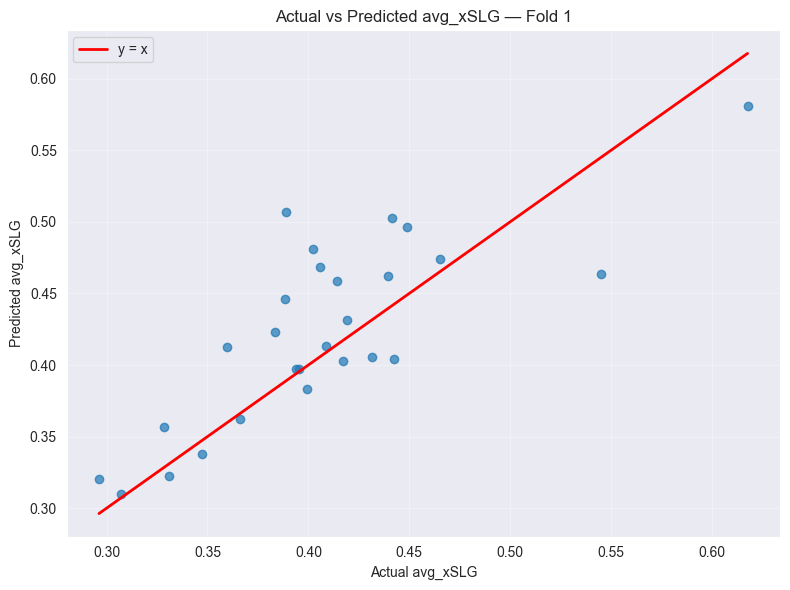

In [560]:
# -------------------------
# Select which fold to plot
# -------------------------
fold_to_plot = 0   # 0-based index → first fold

fold_df = cv_fold_results[fold_to_plot]

actual = fold_df["actual"].to_numpy()
pred   = fold_df["pred"].to_numpy()

plt.figure(figsize=(8, 6))
plt.scatter(actual, pred, alpha=0.7)

# Add y = x reference line
min_val = min(actual.min(), pred.min())
max_val = max(actual.max(), pred.max())
plt.plot([min_val, max_val], [min_val, max_val],
         color="red", linewidth=2, label="y = x")

plt.xlabel(f"Actual {dep_var}")
plt.ylabel(f"Predicted {dep_var}")

plt.title(f"Actual vs Predicted {dep_var} — Fold {fold_to_plot + 1}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


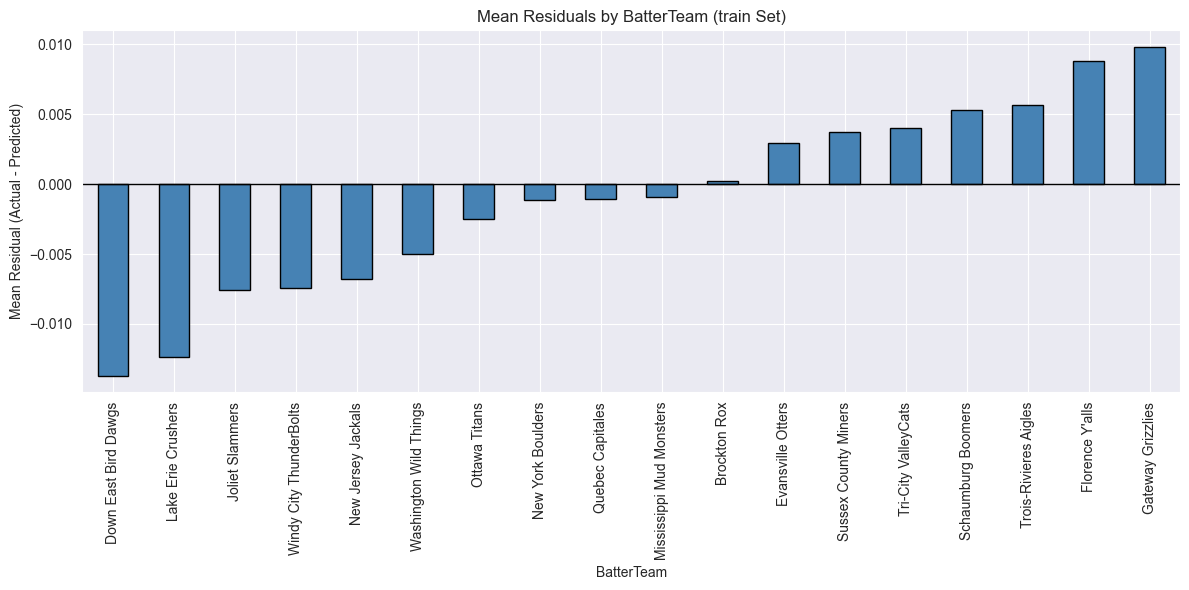

In [561]:
import matplotlib.pyplot as plt

# Residuals
train_residuals = y_train - train_preds

# BatterTeam labels aligned to test indices
train_teams = data.iloc[train_idx]["BatterTeam"].reset_index(drop=True)

# Build DataFrame
train_res_df = pd.DataFrame({
    "BatterTeam": train_teams,
    "residual": train_residuals
})

# Mean residuals by BatterTeam
mean_train_residuals = (
    train_res_df.groupby("BatterTeam")["residual"]
    .mean()
    .sort_values()
)

# Plot
plt.figure(figsize=(12, 6))
mean_train_residuals.plot(kind="bar", color="steelblue", edgecolor="black")

plt.title("Mean Residuals by BatterTeam (train Set)")
plt.ylabel("Mean Residual (Actual - Predicted)")
plt.xlabel("BatterTeam")
plt.axhline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

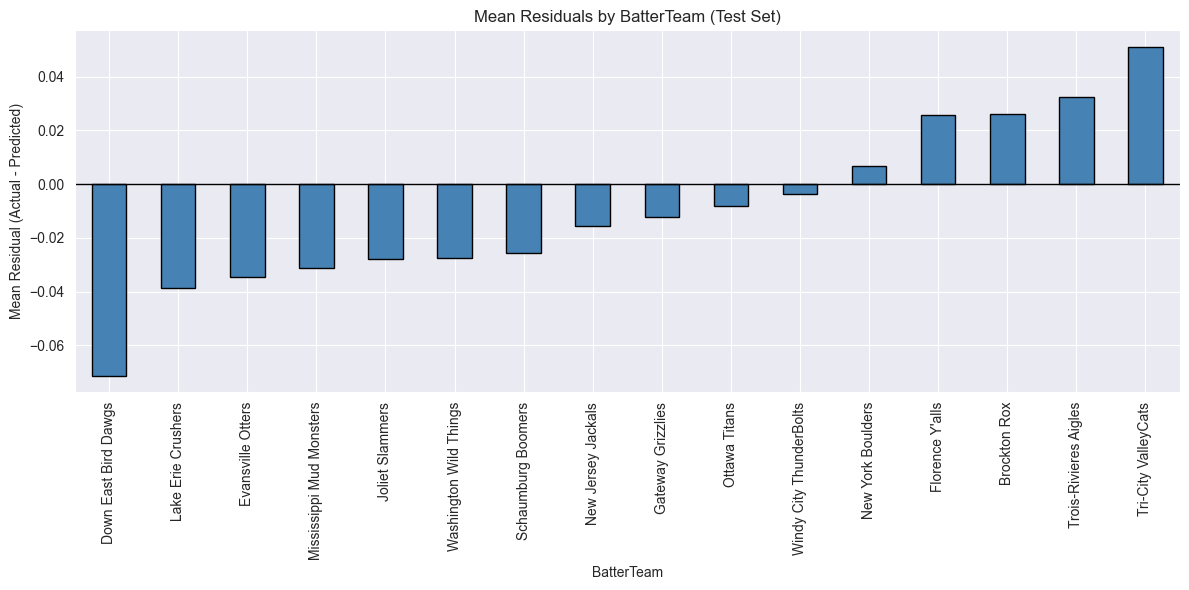

In [562]:
import matplotlib.pyplot as plt

# Residuals
test_residuals = y_test - test_preds

# BatterTeam labels aligned to test indices
test_teams = data.iloc[test_idx]["BatterTeam"].reset_index(drop=True)

# Build DataFrame
test_res_df = pd.DataFrame({
    "BatterTeam": test_teams,
    "residual": test_residuals
})

# Mean residuals by BatterTeam
mean_test_residuals = (
    test_res_df.groupby("BatterTeam")["residual"]
    .mean()
    .sort_values()
)

# Plot
plt.figure(figsize=(12, 6))
mean_test_residuals.plot(kind="bar", color="steelblue", edgecolor="black")

plt.title("Mean Residuals by BatterTeam (Test Set)")
plt.ylabel("Mean Residual (Actual - Predicted)")
plt.xlabel("BatterTeam")
plt.axhline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()


In [499]:
# Residuals
train_residuals = y_train - train_preds
test_residuals  = y_test  - test_preds

# Team labels aligned to each split
train_teams = data.loc[y_train.index, "team"]
test_teams  = data.loc[y_test.index,  "team"]

# Build DataFrames
train_res_df = pd.DataFrame({
    "team": train_teams,
    "residual": train_residuals
})

test_res_df = pd.DataFrame({
    "team": test_teams,
    "residual": test_residuals
})

# Group by team
mean_train_residuals = train_res_df.groupby("team")["residual"].mean().sort_values()
mean_test_residuals  = test_res_df.groupby("team")["residual"].mean().sort_values()

print("Mean residuals by team (TRAINING SET):")
print(mean_train_residuals)

print("\nMean residuals by team (TEST SET):")
print(mean_test_residuals)


AttributeError: 'numpy.ndarray' object has no attribute 'index'

In [444]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [750, 800, 850],
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": [8, 10, 12, 14],
    "min_samples_leaf": [2, 4, 6, 8],
}


In [445]:
rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

rand_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=40,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rand_search.fit(X_train, y_train)

print("Best parameters from RandomizedSearchCV:")
print(rand_search.best_params_)
print("Best CV R²:", rand_search.best_score_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters from RandomizedSearchCV:
{'n_estimators': 800, 'min_samples_split': 8, 'min_samples_leaf': 8, 'max_depth': 15}
Best CV R²: 0.28686375941790815


In [386]:
rf_tuned = rand_search.best_estimator_

test_preds = rf_tuned.predict(X_test)
test_r2 = r2_score(y_test, test_preds)

print("Test-set R² (tuned):", test_r2)


Test-set R² (tuned): 0.43714917688831356


In [289]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Base model
rf = RandomForestRegressor(random_state=42, n_jobs=-1)

# Hyperparameter space
param_dist = {
    "n_estimators": [900, 1000, 1100, 1200],
    "max_depth": [15, 20, 25],
    "min_samples_split": [8, 10, 12, 14],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["auto", "sqrt", 0.5, 0.7, 1.0],
    "bootstrap": [True, False]
}

# Randomized search
rand_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=40,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1
)

rand_search.fit(X, y)

print("Best parameters:", rand_search.best_params_)
print("Best CV R²:", rand_search.best_score_)


C:\Users\215nt\PycharmProjects\FLStuff\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
40 fits failed out of a total of 200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
27 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\215nt\PycharmProjects\FLStuff\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\215nt\PycharmProjects\FLStuff\.venv\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\215nt\PycharmProjects\FLS

Best parameters: {'n_estimators': 1000, 'min_samples_split': 8, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 25, 'bootstrap': True}
Best CV R²: 0.5378708707888231


In [249]:
import statsmodels.api as sm

# Filter to valid ISO values
data_model = data[(data["iso"] > 0) & (data["iso"] < 1)].copy()

# Logit transform ISO
data_model["iso_logit"] = np.log(data_model["iso"] / (1 - data_model["iso"]))

# Train-test split
train_data, test_data = train_test_split(
    data_model,
    test_size=0.2,
    random_state=42
)

# Prepare design matrices
X_train = sm.add_constant(train_data[["Natural_Attack_Angle", "Max_EV"]])
y_train = train_data["iso_logit"]

# Fit linear model
model = sm.OLS(y_train, X_train).fit()
print(model.summary())

# Predict on test set
X_test = sm.add_constant(test_data[["Natural_Attack_Angle", "Max_EV"]])
test_data["iso_pred_logit"] = model.predict(X_test)

# Invert logit transform
test_data["iso_pred"] = 1 / (1 + np.exp(-test_data["iso_pred_logit"]))

# Evaluate
mae = np.mean(np.abs(test_data["iso_pred"] - test_data["iso"]))
rmse = np.sqrt(np.mean((test_data["iso_pred"] - test_data["iso"])**2))

print("Test MAE:", mae)
print("Test RMSE:", rmse)



                            OLS Regression Results                            
Dep. Variable:              iso_logit   R-squared:                       0.547
Model:                            OLS   Adj. R-squared:                  0.541
Method:                 Least Squares   F-statistic:                     104.3
Date:                Mon, 12 Jan 2026   Prob (F-statistic):           1.89e-30
Time:                        22:05:18   Log-Likelihood:                -107.88
No. Observations:                 176   AIC:                             221.8
Df Residuals:                     173   BIC:                             231.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  -11.0698 

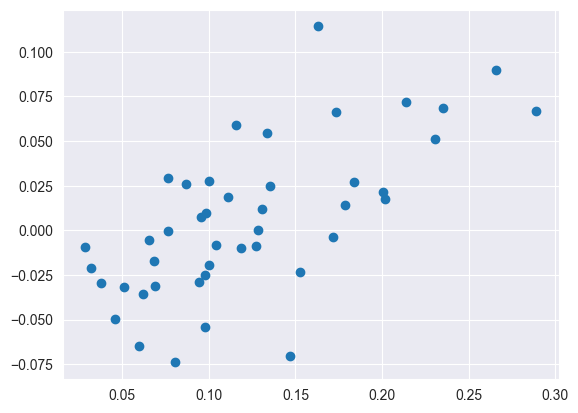

In [256]:
test_data["residual"] = test_data["iso"] - test_data["iso_pred"]
plt.scatter(test_data['iso'], test_data['residual'])

In [254]:
ss_res = np.sum((test_data["iso"] - test_data["iso_pred"])**2)
ss_tot = np.sum((test_data["iso"] - test_data["iso"].mean())**2)
r2 = 1 - ss_res / ss_tot
r2

np.float64(0.5276982418248923)

In [199]:
# Split the *dataframe* directly
train_data, test_data = train_test_split(
    data,
    test_size=0.3,
    random_state=42,
    shuffle=True
)

# Now extract X and y from each split
X_train = train_data[["Natural_Attack_Angle", "Max_EV"]]
y_train = train_data["HR"]

X_test = test_data[["Natural_Attack_Angle", "Max_EV"]]
y_test = test_data["HR"]


In [200]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split



# ----------------------------------------------------
# 3. Fit Binomial GLM on training data
# ----------------------------------------------------
model = smf.glm(
    formula="HR + HR_fail ~ Natural_Attack_Angle + Max_EV",
    data=train_data,
    family=sm.families.Binomial()
).fit()

print(model.summary())

# ----------------------------------------------------
# 4. Predict probability of HR per AB on test set
# ----------------------------------------------------
test_data["p_pred"] = model.predict(test_data)

# Convert predicted probability to predicted HR count
test_data["HR_pred"] = test_data["p_pred"] * test_data["AB"]

# ----------------------------------------------------
# 5. Compute pseudo-R² on test set
# ----------------------------------------------------
y_true = test_data["HR"]
y_pred = test_data["HR_pred"]

ss_res = np.sum((y_true - y_pred)**2)
ss_tot = np.sum((y_true - y_true.mean())**2)

pseudo_r2 = 1 - ss_res / ss_tot

print("Pseudo-R² (test set):", pseudo_r2)



                 Generalized Linear Model Regression Results                  
Dep. Variable:      ['HR', 'HR_fail']   No. Observations:                   61
Model:                            GLM   Df Residuals:                       57
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -145.31
Date:                Mon, 12 Jan 2026   Deviance:                       67.857
Time:                        20:38:10   Pearson chi2:                     66.6
No. Iterations:                     8   Pseudo R-squ. (CS):             0.8608
Covariance Type:            nonrobust                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             -122.3402 

In [201]:
pseudo_r2 = 1 - (model.llf / model.null_deviance / -2)
pseudo_r2

np.float64(0.6138607007532987)

In [202]:
import numpy as np

# Error in HR count
test_data["error"] = test_data["HR_pred"] - test_data["HR"]

# Error in HR/AB rate
test_data["rate_error"] = (
    test_data["p_pred"] - (test_data["HR"] / test_data["AB"])
)


In [203]:
test_data["residual"] = test_data["HR_AB"] - test_data["p_pred"]

test_data["std_residual"] = (
    (test_data["HR_AB"] - test_data["p_pred"]) /
    np.sqrt(test_data["p_pred"] * (1 - test_data["p_pred"]) / test_data["AB"])
)


C:\Users\215nt\AppData\Local\Temp\ipykernel_38736\3961600093.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = test_data.groupby("pred_bin").agg(


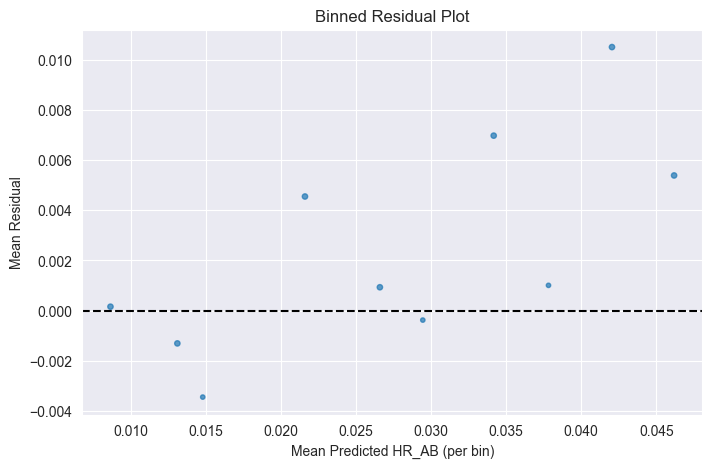

In [204]:
test_data["pred_bin"] = pd.qcut(test_data["p_pred"], q=10, duplicates="drop")

binned = test_data.groupby("pred_bin").agg(
    mean_pred=("p_pred", "mean"),
    mean_resid=("residual", "mean"),
    count=("residual", "size")
)

plt.figure(figsize=(8,5))
plt.scatter(binned["mean_pred"], binned["mean_resid"], s=binned["count"]*5, alpha=0.7)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Mean Predicted HR_AB (per bin)")
plt.ylabel("Mean Residual")
plt.title("Binned Residual Plot")
plt.show()


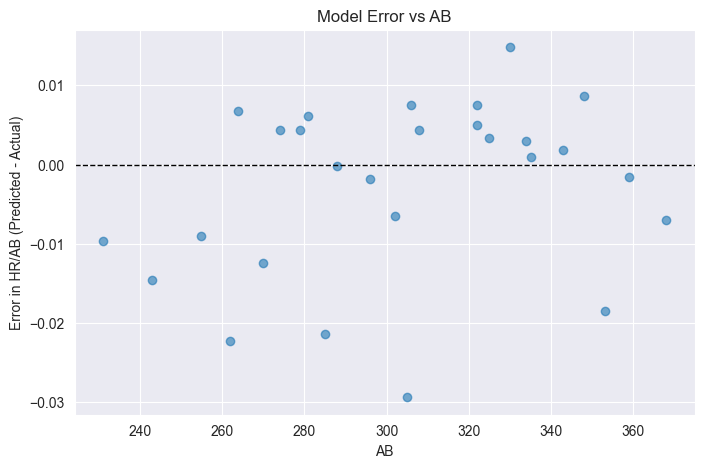

In [205]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(test_data["AB"], test_data["rate_error"], alpha=0.6)
plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("AB")
plt.ylabel("Error in HR/AB (Predicted - Actual)")
plt.title("Model Error vs AB")
plt.show()


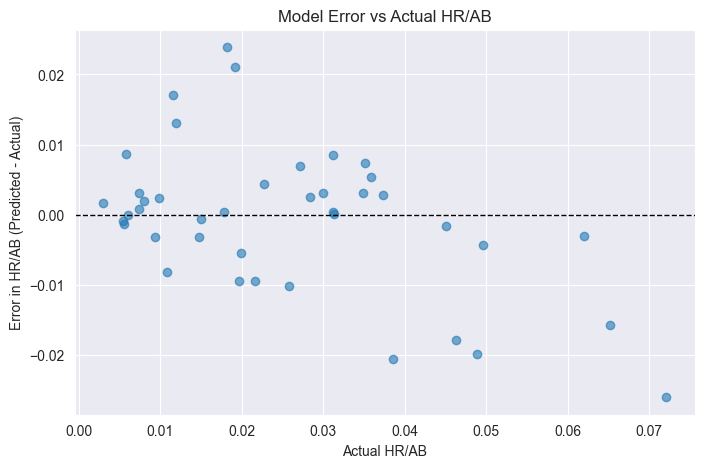

In [188]:
plt.figure(figsize=(8, 5))
plt.scatter(test_data["HR"] / test_data["AB"], test_data["rate_error"], alpha=0.6)
plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("Actual HR/AB")
plt.ylabel("Error in HR/AB (Predicted - Actual)")
plt.title("Model Error vs Actual HR/AB")
plt.show()


In [85]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
import statsmodels.formula.api as smf
import statsmodels.api as sm

kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(data)):
    train_df = data.iloc[train_idx].copy()
    test_df  = data.iloc[test_idx].copy()

    # Recompute HR_fail inside each fold
    train_df["HR_fail"] = train_df["AB"] - train_df["HR"]
    test_df["HR_fail"]  = test_df["AB"] - test_df["HR"]

    # Fit Binomial GLM
    model = smf.glm(
        formula="HR + HR_fail ~ Natural_Attack_Angle + Max_EV + Max_EV_2 + PullFBPct",
        data=train_df,
        family=sm.families.Binomial()
    ).fit()

    # Predict probability of HR per AB
    test_df["p_pred"] = model.predict(test_df)

    # Actual HR/AB
    test_df["p_actual"] = test_df["HR"] / test_df["AB"]

    # RMSE for this fold
    rmse = np.sqrt(np.mean((test_df["p_pred"] - test_df["p_actual"])**2))

    fold_results.append({
        "fold": fold + 1,
        "rmse": rmse
    })

cv_results = pd.DataFrame(fold_results)
print(cv_results)
print("Mean RMSE:", cv_results["rmse"].mean())


   fold      rmse
0     1  0.011501
1     2  0.012879
2     3  0.014464
3     4  0.043442
4     5  0.010381
Mean RMSE: 0.018533545684391653


Binomial GLM (3 Variables)

In [86]:
# Split the *dataframe* directly
train_data, test_data = train_test_split(
    data,
    test_size=0.3,
    random_state=42,
    shuffle=True
)

# Now extract X and y from each split
X_train = train_data[["Natural_Attack_Angle", "Max_EV", "PullAirPct"]]
y_train = train_data["HR"]

X_test = test_data[["Natural_Attack_Angle", "Max_EV", "PullAirPct"]]
y_test = test_data["HR"]

In [87]:
# ----------------------------------------------------
# 3. Fit Binomial GLM on training data
# ----------------------------------------------------
bin_model = smf.glm(
    formula="HR + HR_fail ~ Natural_Attack_Angle + Max_EV + PullAirPct",
    data=train_data,
    family=sm.families.Binomial()
).fit()

print(model.summary())

# ----------------------------------------------------
# 4. Predict probability of HR per AB on test set
# ----------------------------------------------------
test_data["p_pred"] = bin_model.predict(test_data)

# Convert predicted probability to predicted HR count
test_data["HR_pred"] = test_data["p_pred"] * test_data["AB"]

# ----------------------------------------------------
# 5. Compute pseudo-R² on test set
# ----------------------------------------------------
y_true = test_data["HR"]
y_pred = test_data["HR_pred"]

ss_res = np.sum((y_true - y_pred)**2)
ss_tot = np.sum((y_true - y_true.mean())**2)

pseudo_r2 = 1 - ss_res / ss_tot

print("Pseudo-R² (test set):", pseudo_r2)

                 Generalized Linear Model Regression Results                  
Dep. Variable:      ['HR', 'HR_fail']   No. Observations:                  142
Model:                            GLM   Df Residuals:                      139
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -363.22
Date:                Mon, 12 Jan 2026   Deviance:                       248.31
Time:                        20:16:23   Pearson chi2:                     240.
No. Iterations:                     7   Pseudo R-squ. (CS):             0.8066
Covariance Type:            nonrobust                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              -13.7274 

In [88]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(train_data)):
    train_fold = train_data.iloc[train_idx].copy()
    test_fold  = train_data.iloc[test_idx].copy()

    # Recompute HR_fail inside each fold
    train_fold["HR_fail"] = train_fold["AB"] - train_fold["HR"]
    test_fold["HR_fail"]  = test_fold["AB"] - test_fold["HR"]

    # Fit Binomial GLM with PullAirPct added
    model = smf.glm(
        formula="HR + HR_fail ~ Natural_Attack_Angle + Max_EV + PullAirPct",
        data=train_fold,
        family=sm.families.Binomial()
    ).fit()

    # Predict HR/AB
    test_fold["p_pred"] = model.predict(test_fold)

    # Actual HR rate
    test_fold["HR_AB"] = test_fold["HR"] / test_fold["AB"]

    # Residuals
    test_fold["residual"] = test_fold["HR_AB"] - test_fold["p_pred"]

    # RMSE for this fold
    rmse = np.sqrt(np.mean(test_fold["residual"]**2))

    fold_results.append({
        "fold": fold + 1,
        "rmse": rmse
    })

cv_results = pd.DataFrame(fold_results)
print(cv_results)
print("Mean RMSE:", cv_results["rmse"].mean())


   fold      rmse
0     1  0.011733
1     2  0.012533
2     3  0.009440
3     4  0.039422
4     5  0.016465
Mean RMSE: 0.017918585321854523


In [89]:
test_data["residual"] = test_data["HR_AB"] - test_data["p_pred"]


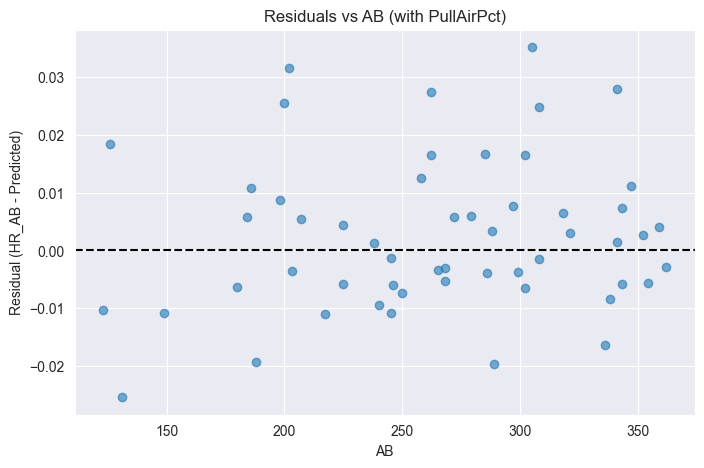

In [90]:
plt.figure(figsize=(8,5))
plt.scatter(test_data["AB"], test_data["residual"], alpha=0.6)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("AB")
plt.ylabel("Residual (HR_AB - Predicted)")
plt.title("Residuals vs AB (with PullAirPct)")
plt.show()


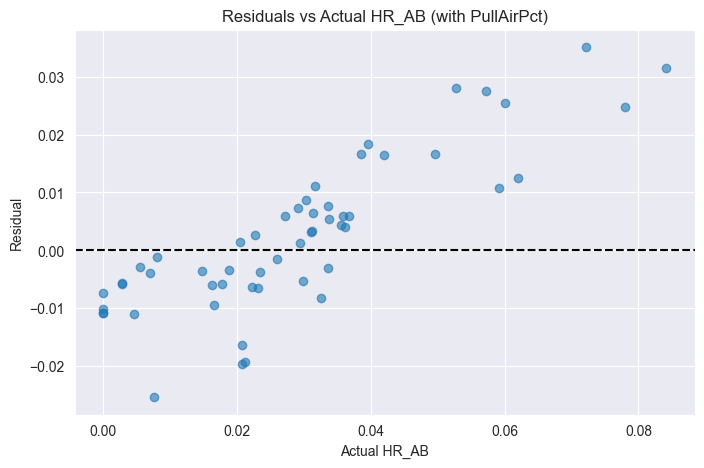

In [91]:
plt.figure(figsize=(8,5))
plt.scatter(test_data["HR_AB"], test_data["residual"], alpha=0.6)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Actual HR_AB")
plt.ylabel("Residual")
plt.title("Residuals vs Actual HR_AB (with PullAirPct)")
plt.show()


In [144]:
# Influence diagnostics
influence = bin_model.get_influence()

# Cook's distance
cooks_d = influence.cooks_distance[0]

# Leverage
leverage = influence.hat_matrix_diag

# DFBETAs
dfbetas = influence.dfbetas

# Deviance residuals
resid_dev = bin_model.resid_deviance

In [155]:
def glm_influence_plots(model, X, y, id_col=None):
    """
    Generate influence diagnostics for a binomial GLM.

    Parameters
    ----------
    model : statsmodels GLMResults
        Fitted GLM model (family=Binomial)
    X : pandas DataFrame
        Design matrix used to fit the model
    y : pandas Series or array
        Response variable
    id_col : pandas Series (optional)
        Identifier for labeling outliers (e.g., pitcher name)
    """

    influence = model.get_influence()

    # Extract diagnostics
    cooks_d = influence.cooks_distance[0]
    leverage = influence.hat_matrix_diag
    resid_dev = model.resid_deviance
    dfbetas = influence.dfbetas

    fitted = model.fittedvalues

    # -----------------------------
    # 1. Residuals vs Fitted
    # -----------------------------
    plt.figure(figsize=(7,5))
    plt.scatter(fitted, resid_dev, alpha=0.6)
    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Fitted Values")
    plt.ylabel("Deviance Residuals")
    plt.title("Residuals vs Fitted")
    plt.tight_layout()
    plt.show()

    # -----------------------------
    # 2. Cook's Distance
    # -----------------------------
    plt.figure(figsize=(7,5))
    plt.stem(np.arange(len(cooks_d)), cooks_d, markerfmt=" ", basefmt=" ")
    plt.xlabel("Observation")
    plt.ylabel("Cook's Distance")
    plt.title("Cook's Distance")
    plt.tight_layout()
    plt.show()

    # -----------------------------
    # 3. Leverage vs Residuals
    # -----------------------------
    plt.figure(figsize=(7,5))
    plt.scatter(leverage, resid_dev, alpha=0.6)
    plt.xlabel("Leverage")
    plt.ylabel("Deviance Residuals")
    plt.title("Leverage vs Residuals")
    plt.tight_layout()
    plt.show()

    # -----------------------------
    # 4. Influence Index Plot
    # -----------------------------
    fig, ax = plt.subplots(figsize=(8,5))
    ax.scatter(np.arange(len(cooks_d)), cooks_d, label="Cook's D")
    ax.scatter(np.arange(len(leverage)), leverage, label="Leverage")
    ax.set_title("Influence Index Plot")
    ax.set_xlabel("Observation")
    ax.legend()
    plt.tight_layout()
    plt.show()


    # -----------------------------
    # 6. DFBETAs Heatmap
    # -----------------------------
    dfbetas_df = pd.DataFrame(dfbetas, columns=X.columns)

    plt.figure(figsize=(10,6))
    sns.heatmap(dfbetas_df.T, cmap="coolwarm", center=0)
    plt.title("DFBETAs Heatmap")
    plt.xlabel("Observation")
    plt.ylabel("Coefficient")
    plt.tight_layout()
    plt.show()


C:\Users\215nt\AppData\Local\Temp\ipykernel_157964\1402091965.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = test_data.groupby("pred_bin").agg(


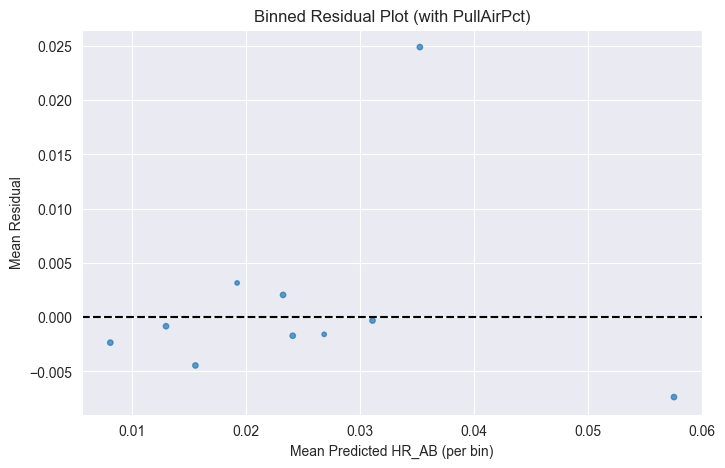

In [83]:
test_data["pred_bin"] = pd.qcut(test_data["p_pred"], q=10, duplicates="drop")

binned = test_data.groupby("pred_bin").agg(
    mean_pred=("p_pred", "mean"),
    mean_resid=("residual", "mean"),
    count=("residual", "size")
)

plt.figure(figsize=(8,5))
plt.scatter(binned["mean_pred"], binned["mean_resid"],
            s=binned["count"]*5, alpha=0.7)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Mean Predicted HR_AB (per bin)")
plt.ylabel("Mean Residual")
plt.title("Binned Residual Plot (with PullAirPct)")
plt.show()


In [146]:
wilder = train_data.loc[["Wilder, Ethan"]].copy()
wilder["HR_fail"] = wilder["AB"] - wilder["HR"]

wilder_pred = model.predict(wilder)[0]
wilder_pred



C:\Users\215nt\AppData\Local\Temp\ipykernel_2812\4247644256.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wilder_pred = model.predict(wilder)[0]


np.float64(0.009672242166997375)

In [148]:
train_data.loc[["Wilder, Ethan"]]

,Team,HR,Natural_Attack_Angle,Max_EV,BBE,AB,HR_AB,PullPct,PullAirPct,BABIP,Max_EV_PullAirPct,AttackAngle_PullAirPct,Max_EV_AttackAngle,log_HR_AB,HR_fail
"Wilder, Ethan",Washington Wild Things,2,12.0,99.554569,211,283,0.007067,0.241706,0.028436,0.348837,2.830936,0.341232,1194.654824,-2.380609,281


In [176]:
import scipy.stats as stats


stats.percentileofscore(data["Natural_Attack_Angle"], 12)


np.float64(36.574074074074076)

In [177]:
stats.percentileofscore(data["Max_EV"], 99.555)

np.float64(20.37037037037037)

In [180]:
stats.percentileofscore(data["PullPct"], 0.241)

np.float64(3.240740740740741)

In [178]:
stats.percentileofscore(data["PullAirPct"], 0.0284)

np.float64(0.9259259259259259)

In [186]:
stats.percentileofscore(data["HR_AB"], .009)

np.float64(22.685185185185187)

In [184]:
0.009672242166997375*283/295

0.009278795028000872

In [174]:
0.009672242166997375*283

2.7372445332602573

In [181]:
data['PullPct'].describe()

count    216.000000
mean       0.388245
std        0.077732
min        0.138614
25%        0.342690
50%        0.390524
75%        0.440006
max        0.610687
Name: PullPct, dtype: float64

In [153]:
data['PullAirPct'].describe()

count    216.000000
mean       0.131567
std        0.050481
min        0.014870
25%        0.094512
50%        0.129454
75%        0.168348
max        0.290076
Name: PullAirPct, dtype: float64

In [152]:
data['HR_AB'].describe()

count    216.000000
mean       0.024362
std        0.017828
min        0.000000
25%        0.009804
50%        0.022388
75%        0.033479
max        0.085427
Name: HR_AB, dtype: float64

In [154]:
data['Natural_Attack_Angle'].describe()

count    216.000000
mean      13.495370
std        5.533721
min      -10.500000
25%       10.000000
50%       13.750000
75%       17.250000
max       29.000000
Name: Natural_Attack_Angle, dtype: float64

In [173]:
data['Max_EV'].describe()

count    216.000000
mean     102.658277
std        3.501270
min       94.896069
25%       99.849455
50%      102.910017
75%      105.065213
max      113.413645
Name: Max_EV, dtype: float64

Binomial GLM (3 Variables, Interactions)

In [ ]:
formula = "HR + HR_fail ~ (Natural_Attack_Angle + Max_EV + PullAirPct)**2"


In [155]:
formula = """
HR + HR_fail ~ Natural_Attack_Angle + Max_EV + PullAirPct
+ Natural_Attack_Angle:Max_EV
+ Natural_Attack_Angle:PullAirPct
+ Max_EV:PullAirPct
"""

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(train_data)):
    train_fold = train_data.iloc[train_idx].copy()
    test_fold  = train_data.iloc[test_idx].copy()

    train_fold["HR_fail"] = train_fold["AB"] - train_fold["HR"]
    test_fold["HR_fail"]  = test_fold["AB"] - test_fold["HR"]

    model = smf.glm(
        formula=formula,
        data=train_fold,
        family=sm.families.Binomial()
    ).fit()

    test_fold["p_pred"] = model.predict(test_fold)
    test_fold["HR_AB"] = test_fold["HR"] / test_fold["AB"]
    test_fold["residual"] = test_fold["HR_AB"] - test_fold["p_pred"]

    rmse = np.sqrt(np.mean(test_fold["residual"]**2))

    fold_results.append({"fold": fold + 1, "rmse": rmse})

cv_results = pd.DataFrame(fold_results)
print(cv_results)
print("Mean RMSE:", cv_results["rmse"].mean())


   fold      rmse
0     1  0.011928
1     2  0.010030
2     3  0.016502
3     4  0.010237
4     5  0.008318
Mean RMSE: 0.01140308737425343


In [157]:
print(model.params)


Intercept                         -20.546346
Natural_Attack_Angle                0.026288
Max_EV                              0.149020
PullAirPct                         30.380642
Natural_Attack_Angle:Max_EV         0.000387
Natural_Attack_Angle:PullAirPct    -0.220763
Max_EV:PullAirPct                  -0.227356
dtype: float64


In [156]:
wilder = train_data.loc[["Wilder, Ethan"]].copy()
wilder["HR_fail"] = wilder["AB"] - wilder["HR"]

wilder_pred = model.predict(wilder)[0]
print(f"Predicted HR/AB for Wilder, Ethan: {wilder_pred:.4f}")


Predicted HR/AB for Wilder, Ethan: 0.0083


C:\Users\215nt\AppData\Local\Temp\ipykernel_2812\625456895.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wilder_pred = model.predict(wilder)[0]


In [158]:
cols = ["Natural_Attack_Angle", "Max_EV", "PullAirPct"]

for col in cols:
    mean = train_data[col].mean()
    std = train_data[col].std()
    train_data[col + "_z"] = (train_data[col] - mean) / std

In [159]:
formula = """
HR + HR_fail ~ Natural_Attack_Angle_z + Max_EV_z + PullAirPct_z
+ Natural_Attack_Angle_z:Max_EV_z
+ Natural_Attack_Angle_z:PullAirPct_z
+ Max_EV_z:PullAirPct_z
"""


In [160]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(train_data)):
    train_fold = train_data.iloc[train_idx].copy()
    test_fold  = train_data.iloc[test_idx].copy()

    # Recompute HR_fail
    train_fold["HR_fail"] = train_fold["AB"] - train_fold["HR"]
    test_fold["HR_fail"]  = test_fold["AB"] - test_fold["HR"]

    # Scale inside each fold (important!)
    for col in ["Natural_Attack_Angle", "Max_EV", "PullAirPct"]:
        mean = train_fold[col].mean()
        std = train_fold[col].std()

        train_fold[col + "_z"] = (train_fold[col] - mean) / std
        test_fold[col + "_z"]  = (test_fold[col] - mean) / std

    # Fit GLM with interactions
    model = smf.glm(
        formula=formula,
        data=train_fold,
        family=sm.families.Binomial()
    ).fit()

    # Predict HR/AB
    test_fold["p_pred"] = model.predict(test_fold)
    test_fold["HR_AB"] = test_fold["HR"] / test_fold["AB"]
    test_fold["residual"] = test_fold["HR_AB"] - test_fold["p_pred"]

    rmse = np.sqrt(np.mean(test_fold["residual"]**2))

    fold_results.append({"fold": fold + 1, "rmse": rmse})

cv_results = pd.DataFrame(fold_results)
print(cv_results)
print("Mean RMSE:", cv_results["rmse"].mean())


   fold      rmse
0     1  0.011928
1     2  0.010030
2     3  0.016502
3     4  0.010237
4     5  0.008318
Mean RMSE: 0.011403087374253298


In [161]:
print(model.params)

Intercept                             -3.800606
Natural_Attack_Angle_z                 0.210991
Max_EV_z                               0.435031
PullAirPct_z                           0.213775
Natural_Attack_Angle_z:Max_EV_z        0.007954
Natural_Attack_Angle_z:PullAirPct_z   -0.067563
Max_EV_z:PullAirPct_z                 -0.042039
dtype: float64


With Splines

In [168]:
from patsy import bs


formula = """
HR + HR_fail ~
    bs(Max_EV_z, df=4) +
    bs(PullAirPct_z, df=4) +
    Natural_Attack_Angle_z
"""



In [172]:
from sklearn.model_selection import KFold
from patsy import bs
import statsmodels.formula.api as smf
import statsmodels.api as sm
import numpy as np
import pandas as pd

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(train_data)):
    train_fold = train_data.iloc[train_idx].copy()
    test_fold  = train_data.iloc[test_idx].copy()

    # Recompute HR_fail
    train_fold["HR_fail"] = train_fold["AB"] - train_fold["HR"]
    test_fold["HR_fail"]  = test_fold["AB"] - test_fold["HR"]

    # Scale inside fold
    for col in ["Natural_Attack_Angle", "Max_EV", "PullAirPct"]:
        mean = train_fold[col].mean()
        std  = train_fold[col].std()

        train_fold[col + "_z"] = (train_fold[col] - mean) / std
        test_fold[col + "_z"]  = (test_fold[col] - mean) / std

    # Boundary knots for splines
    maxev_min = train_fold["Max_EV_z"].min()
    maxev_max = train_fold["Max_EV_z"].max()

    pap_min = train_fold["PullAirPct_z"].min()
    pap_max = train_fold["PullAirPct_z"].max()

    # --- Max EV spline ---
    maxev_train = bs(train_fold["Max_EV_z"],
                     df=4,
                     lower_bound=maxev_min,
                     upper_bound=maxev_max,
                     include_intercept=False)

    maxev_test = bs(test_fold["Max_EV_z"],
                    df=4,
                    lower_bound=maxev_min,
                    upper_bound=maxev_max,
                    include_intercept=False)

    maxev_train_df = pd.DataFrame(
        maxev_train,
        index=train_fold.index,
        columns=[f"MaxEV_s{i}" for i in range(maxev_train.shape[1])]
    )

    maxev_test_df = pd.DataFrame(
        maxev_test,
        index=test_fold.index,
        columns=[f"MaxEV_s{i}" for i in range(maxev_test.shape[1])]
    )

    train_fold = pd.concat([train_fold, maxev_train_df], axis=1)
    test_fold  = pd.concat([test_fold,  maxev_test_df],  axis=1)

    # --- PullAirPct spline ---
    pull_train = bs(train_fold["PullAirPct_z"],
                    df=4,
                    lower_bound=pap_min,
                    upper_bound=pap_max,
                    include_intercept=False)

    pull_test = bs(test_fold["PullAirPct_z"],
                   df=4,
                   lower_bound=pap_min,
                   upper_bound=pap_max,
                   include_intercept=False)

    pull_train_df = pd.DataFrame(
        pull_train,
        index=train_fold.index,
        columns=[f"PullAir_s{i}" for i in range(pull_train.shape[1])]
    )

    pull_test_df = pd.DataFrame(
        pull_test,
        index=test_fold.index,
        columns=[f"PullAir_s{i}" for i in range(pull_test.shape[1])]
    )

    train_fold = pd.concat([train_fold, pull_train_df], axis=1)
    test_fold  = pd.concat([test_fold,  pull_test_df],  axis=1)

    # Build formula using explicit spline columns
    spline_cols = (
        " + ".join([f"MaxEV_s{i}" for i in range(maxev_train.shape[1])]) +
        " + " +
        " + ".join([f"PullAir_s{i}" for i in range(pull_train.shape[1])])
    )

    formula = f"""
        HR + HR_fail ~
            {spline_cols} +
            Natural_Attack_Angle_z
    """

    # Fit GLM
    model = smf.glm(
        formula=formula,
        data=train_fold,
        family=sm.families.Binomial()
    ).fit()

    # Predict HR/AB
    test_fold["p_pred"] = model.predict(test_fold)
    test_fold["HR_AB"] = test_fold["HR"] / test_fold["AB"]
    test_fold["residual"] = test_fold["HR_AB"] - test_fold["p_pred"]

    rmse = np.sqrt(np.mean(test_fold["residual"]**2))
    fold_results.append({"fold": fold + 1, "rmse": rmse})

# Results
cv_results = pd.DataFrame(fold_results)
print(cv_results)
print("Mean RMSE:", cv_results["rmse"].mean())



ValueError: zero-size array to reduction operation maximum which has no identity

Lin Reg HR/AB 2 Variable

In [130]:
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)
X = sm.add_constant(X)

In [131]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [7]:
model = sm.OLS(y_train, X_train).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  HR_AB   R-squared:                       0.610
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     126.9
Date:                Tue, 06 Jan 2026   Prob (F-statistic):           7.01e-34
Time:                        21:19:30   Log-Likelihood:                 508.63
No. Observations:                 165   AIC:                            -1011.
Df Residuals:                     162   BIC:                            -1002.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0237      0.001     27.188      0.000       0.022       0.025
x1             0.0051      0.001      5.731      0.000       0.003       0.007
x2             0.0112      0.001     12.291      0.000       0.009       0.013
==============================================================================
Omnibus:                        9.214   Durbin-Watson:                   2.080
Prob(Omnibus):                  0.010   Jarque-Bera (JB):               10.189
Skew:                           0.436   Prob(JB):                      0.00613
Kurtosis:                       3.850   Cond. No.                         1.40
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [8]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(model.resid, model.model.exog)
print(bp_test)  # (LM stat, p-value, F-stat, F p-value)

(np.float64(1.93932055358354), np.float64(0.3792118432871052), np.float64(0.9633528167156157), np.float64(0.3837863958945418))


In [9]:
from sklearn.metrics import mean_squared_error, r2_score

mse_train = mean_squared_error(y_train, model.predict(X_train))
print(f"Train MSE: {mse_train:.6f}")

Train MSE: 0.000123


In [10]:
y_pred = model.predict(X_test)

# Evaluate on test set
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {mse:.6f}")
print(f"Test R²: {r2:.3f}")

Test MSE: 0.000155
Test R²: 0.538


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

sklearn_model = LinearRegression()

In [12]:
cross_val_score(sklearn_model, X, y, cv=5, scoring='r2').mean()

np.float64(0.5636312465978243)

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

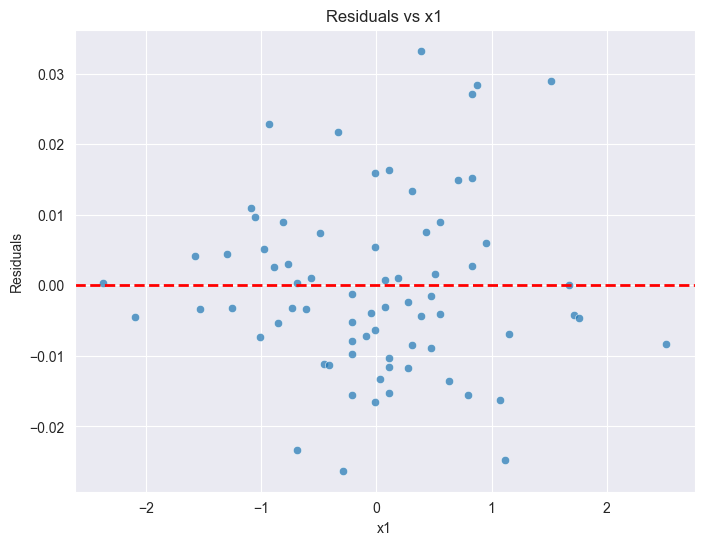

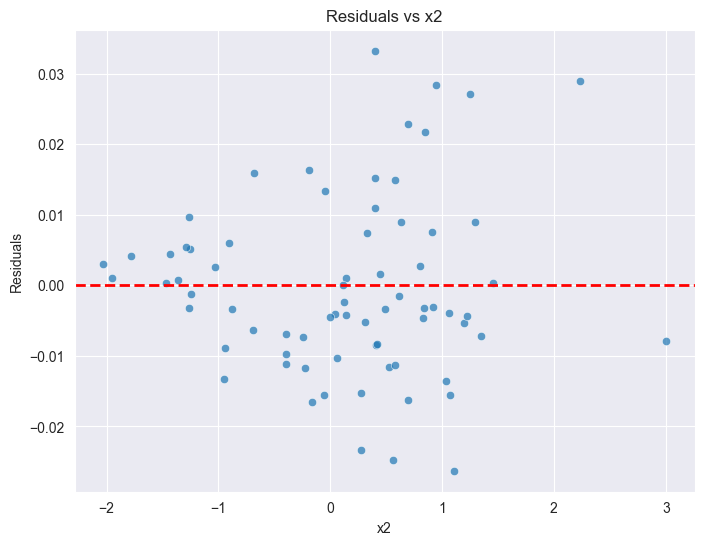

In [14]:
# residuals
residuals = y_test - y_pred

# Get feature names from the model, excluding the constant
feature_names = model.model.exog_names[1:]

# Assuming X_test is a NumPy array and has columns in the same order as feature_names
# We start from index 1 for X_test because the first column is the added constant
for i, col_name in enumerate(feature_names):
    plt.figure(figsize=(8,6))
    sns.scatterplot(x=X_test[:, i+1], y=residuals, alpha=0.7) # Adjust index for the constant column
    plt.axhline(0, color='red', linestyle='--', linewidth=2)
    plt.xlabel(col_name)
    plt.ylabel("Residuals")
    plt.title(f"Residuals vs {col_name}")
    plt.show()

Yeo-Johnson Transformed HR/AB Model (2 Variables)

In [15]:
from sklearn.preprocessing import PowerTransformer

# Initialize PowerTransformer with Yeo-Johnson
pt = PowerTransformer(method='yeo-johnson', standardize=True)

# Fit and transform (reshape Series to 2D)
y_transformed = pt.fit_transform(y.values.reshape(-1, 1))

# Convert back to Series for convenience
y_transformed = pd.Series(y_transformed.ravel(), index=y.index)

print("Original Series:\n", y)
print("\nTransformed Series:\n", y_transformed)
print("\nLambda used:", pt.lambdas_)



Original Series:
 Acevedo, Luis           0.019608
Agresti, Jason          0.038710
Alexander, Sebastian    0.009709
Alvarez, Jose           0.006993
Angelo, Sam             0.025862
                          ...   
Wright, AJ              0.031250
Wright, Taylor          0.016216
Ybarra, Jeter           0.024096
Zeisler, Hank           0.067073
Zimmerman, Will         0.025510
Name: HR_AB, Length: 237, dtype: float64

Transformed Series:
 Acevedo, Luis          -0.070016
Agresti, Jason          0.957468
Alexander, Sebastian   -0.776650
Alvarez, Jose          -0.996264
Angelo, Sam             0.309796
                          ...   
Wright, AJ              0.601409
Wright, Taylor         -0.296577
Ybarra, Jeter           0.207288
Zeisler, Hank           1.925405
Zimmerman, Will         0.289653
Length: 237, dtype: float64

Lambda used: [-19.25762369]


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y_transformed, test_size=0.3, random_state=42)

In [17]:
model = sm.OLS(y_train, X_train).fit()
bp_test = het_breuschpagan(model.resid, model.model.exog)
print(bp_test)  # (LM stat, p-value, F-stat, F p-value)

(np.float64(2.166097016909594), np.float64(0.33856184221068014), np.float64(1.0775020137415572), np.float64(0.3428719547701839))


In [18]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.621
Method:                 Least Squares   F-statistic:                     135.3
Date:                Tue, 06 Jan 2026   Prob (F-statistic):           2.80e-35
Time:                        21:19:31   Log-Likelihood:                -152.91
No. Observations:                 165   AIC:                             311.8
Df Residuals:                     162   BIC:                             321.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0078      0.048      0.161      0.872      -0.087       0.103
x1             0.3098      0.049      6.374      0.000       0.214       0.406
x2             0.6231      0.050     12.375      0.000       0.524       0.723
==============================================================================
Omnibus:                        4.728   Durbin-Watson:                   2.065
Prob(Omnibus):                  0.094   Jarque-Bera (JB):                4.429
Skew:                          -0.302   Prob(JB):                        0.109
Kurtosis:                       3.528   Cond. No.                         1.40
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

HR/AB Model (With PullAir%)

In [19]:
mse_train = mean_squared_error(y_train, model.predict(X_train))
print(f"Train MSE: {mse_train:.3f}")

Train MSE: 0.374


In [20]:
y_pred = model.predict(X_test)

# Evaluate on test set
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {mse:.3f}")
print(f"Test R²: {r2:.3f}")

Test MSE: 0.412
Test R²: 0.589


In [21]:
cross_val_score(sklearn_model, X, y_transformed, cv=5, scoring='r2')

array([0.62572658, 0.65105633, 0.51483593, 0.59868737, 0.59291866])

In [22]:
cross_val_score(sklearn_model, X, y_transformed, cv=5, scoring='r2').mean()

np.float64(0.5966449748526305)

Transformed HR/AB Model (With Pull Air%)

In [23]:
X = data[['Natural_Attack_Angle', 'Max_EV', 'PullAirPct']]

In [24]:
X = scaler.fit_transform(X)
X = sm.add_constant(X)

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y_transformed, test_size=0.3, random_state=42)

In [26]:
model = sm.OLS(y_train, X_train).fit()
bp_test = het_breuschpagan(model.resid, model.model.exog)
print(bp_test)  # (LM stat, p-value, F-stat, F p-value)

(np.float64(4.717405675846619), np.float64(0.19369880012118426), np.float64(1.579506739359979), np.float64(0.1964071301930202))


In [27]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.682
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     115.1
Date:                Tue, 06 Jan 2026   Prob (F-statistic):           7.57e-40
Time:                        21:19:31   Log-Likelihood:                -139.45
No. Observations:                 165   AIC:                             286.9
Df Residuals:                     161   BIC:                             299.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0029      0.044      0.066      0.948      -0.085       0.091
x1             0.2026      0.049      4.117      0.000       0.105       0.300
x2             0.6033      0.047     12.919      0.000       0.511       0.696
x3             0.2634      0.049      5.343      0.000       0.166       0.361
==============================================================================
Omnibus:                        7.679   Durbin-Watson:                   2.102
Prob(Omnibus):                  0.022   Jarque-Bera (JB):                9.764
Skew:                          -0.302   Prob(JB):                      0.00758
Kurtosis:                       4.027   Cond. No.                         1.75
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [28]:
mse_train = mean_squared_error(y_train, model.predict(X_train))
print(f"Train MSE: {mse_train:.3f}")

Train MSE: 0.317


In [29]:
y_pred = model.predict(X_test)

# Evaluate on test set
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {mse:.3f}")
print(f"Test R²: {r2:.3f}")

Test MSE: 0.389
Test R²: 0.611


In [30]:
cross_val_score(sklearn_model, X, y_transformed, cv=5, scoring='r2')

array([0.69401375, 0.65212696, 0.59260601, 0.6591733 , 0.63185778])

In [31]:
cross_val_score(sklearn_model, X, y_transformed, cv=5, scoring='r2').mean()

np.float64(0.6459555597206663)

Robust Transformed HR/AB Model (3 Variables)


In [32]:
import statsmodels.api as sm

# Robust regression with Huber T norm
robust_model = sm.RLM(y_train, X_train, M=sm.robust.norms.HuberT()).fit()

print(robust_model.summary())

                    Robust linear Model Regression Results                    
Dep. Variable:                      y   No. Observations:                  165
Model:                            RLM   Df Residuals:                      161
Method:                          IRLS   Df Model:                            3
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Tue, 06 Jan 2026                                         
Time:                        21:19:31                                         
No. Iterations:                    20                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0134      0.042      0.315      0.7

In [33]:
y_pred_train = robust_model.predict(X_train)
print("Train MSE:", mean_squared_error(y_train, y_pred_train))
print("Train R²:", r2_score(y_train, y_pred_train))

Train MSE: 0.3188721646183966
Train R²: 0.6804435145833654


In [34]:
y_pred = robust_model.predict(X_test)
print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test R²:", r2_score(y_test, y_pred))


Test MSE: 0.3956281588544226
Test R²: 0.6046113838386598


**Final Model:** Robust Transformed HR/AB Model with Max_EV*Attack Angle Interaction

In [35]:
data['Max_EV_Attack_Angle'] = data['Max_EV']*data['Natural_Attack_Angle']

X = data[['Natural_Attack_Angle', 'Max_EV', 'PullAirPct', 'Max_EV_Attack_Angle']]

In [36]:
X = scaler.fit_transform(X)
X = sm.add_constant(X)

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y_transformed, test_size=0.3, random_state=42)

In [38]:
# Robust regression with Huber T norm
robust_model = sm.RLM(y_train, X_train, M=sm.robust.norms.HuberT()).fit()

print(robust_model.summary())

                    Robust linear Model Regression Results                    
Dep. Variable:                      y   No. Observations:                  165
Model:                            RLM   Df Residuals:                      160
Method:                          IRLS   Df Model:                            4
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Tue, 06 Jan 2026                                         
Time:                        21:19:31                                         
No. Iterations:                    15                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0119      0.043      0.279      0.7

In [39]:
y_pred_train = robust_model.predict(X_train)
print("Train MSE:", mean_squared_error(y_train, y_pred_train))
print("Train R²:", r2_score(y_train, y_pred_train))

Train MSE: 0.3051995489039209
Train R²: 0.6941454726373046


In [68]:
y_train_hat = robust_model.fittedvalues
ybar = y_train_hat.mean()


In [69]:
ll_full = robust_model.llf
ll_null = robust_model.model.fit(scale_est=robust_model.scale,
                                M=robust_model.model.M,
                                start_params=[y.mean()] + [0]*(X.shape[1]-1)).llf

pseudo_r2 = 1 - ll_full / ll_null


NotImplementedError: 

In [40]:
y_pred = robust_model.predict(X_test)
print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test R²:", r2_score(y_test, y_pred))

Test MSE: 0.3882132923717634
Test R²: 0.6120217608100282


In [41]:
from sklearn.linear_model import HuberRegressor

skl_huber_model = HuberRegressor()
skl_huber_model.fit(X_train, y_train)

,epsilon,1.35
,max_iter,100
,alpha,0.0001
,warm_start,False
,fit_intercept,True
,tol,1e-05


In [42]:
cross_val_score(skl_huber_model, X, y_transformed, cv=5, scoring='r2')

array([0.71069082, 0.68769079, 0.59133029, 0.66715602, 0.62315174])

In [43]:
cross_val_score(skl_huber_model, X, y_transformed, cv=5, scoring='r2').mean()

np.float64(0.6560039322639178)

Robust Transformed HR/AB Model with Max_EV*PullAirPct Interaction

In [44]:
data['Max_EV_PullAirPct'] = data['Max_EV']*data['PullAirPct']

X = data[['Natural_Attack_Angle', 'Max_EV', 'PullAirPct', 'Max_EV_Attack_Angle', 'Max_EV_PullAirPct']]

In [45]:
X = scaler.fit_transform(X)
X = sm.add_constant(X)

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y_transformed, test_size=0.3, random_state=42)

In [47]:
# Robust regression with Huber T norm
robust_model = sm.RLM(y_train, X_train, M=sm.robust.norms.HuberT()).fit()

print(robust_model.summary())

                    Robust linear Model Regression Results                    
Dep. Variable:                      y   No. Observations:                  165
Model:                            RLM   Df Residuals:                      159
Method:                          IRLS   Df Model:                            5
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Tue, 06 Jan 2026                                         
Time:                        21:19:32                                         
No. Iterations:                    14                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0156      0.043      0.364      0.7

Robust Transformed HR/AB Model with Attack_Angle*PullAirPct Interaction

In [48]:
data['Attack_Angle_PullAirPct'] = data['Natural_Attack_Angle']*data['PullAirPct']

X = data[['Natural_Attack_Angle', 'Max_EV', 'PullAirPct', 'Max_EV_Attack_Angle', 'Attack_Angle_PullAirPct']]

In [49]:
X = scaler.fit_transform(X)
X = sm.add_constant(X)

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y_transformed, test_size=0.3, random_state=42)

In [51]:
# Robust regression with Huber T norm
robust_model = sm.RLM(y_train, X_train, M=sm.robust.norms.HuberT()).fit()

print(robust_model.summary())

                    Robust linear Model Regression Results                    
Dep. Variable:                      y   No. Observations:                  165
Model:                            RLM   Df Residuals:                      159
Method:                          IRLS   Df Model:                            5
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Tue, 06 Jan 2026                                         
Time:                        21:19:32                                         
No. Iterations:                    15                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0112      0.042      0.270      0.7

Gamma GLM Log-Link

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [53]:
# Binary indicator: 1 if positive, 0 if zero
y_train_pos = (y_train > 0).astype(int)
y_test_pos  = (y_test > 0).astype(int)


In [54]:
from sklearn.linear_model import LogisticRegression

logit = LogisticRegression(max_iter=500)
logit.fit(X_train, y_train_pos)

# Probability that Y > 0
p_pos_test = logit.predict_proba(X_test)[:, 1]


In [55]:
from sklearn.linear_model import TweedieRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Filter training data to positive responses only
mask_train = y_train > 0
X_train_pos = X_train[mask_train]
y_train_pos_values = y_train[mask_train]

gamma_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("glm", TweedieRegressor(power=2, link="log"))
])

gamma_pipe.fit(X_train_pos, y_train_pos_values)

# Predict conditional mean E[Y | Y>0]
mu_test = gamma_pipe.predict(X_test)


In [56]:
# Final hurdle model prediction
y_pred = p_pos_test * mu_test


In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("MAE:", mae)
print("RMSE:", rmse)
print("MSE: ", mse)



MAE: 0.010108262379715066
RMSE: 0.01322170004509609
MSE:  0.00017481335208249392


In [70]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Linear Regression predictions
y_pred_lr = model.predict(X_test)

# Hurdle model predictions
y_pred_hurdle = y_pred  # from earlier

# Metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mae_hurdle = mean_absolute_error(y_test, y_pred_hurdle)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
rmse_hurdle = np.sqrt(mean_squared_error(y_test, y_pred_hurdle))

# Efron pseudo-R²
def efron_r2(y, yhat):
    return 1 - np.sum((y - yhat)**2) / np.sum((y - np.mean(y))**2)

r2_lr = efron_r2(y_test, y_pred_lr)
r2_hurdle = efron_r2(y_test, y_pred_hurdle)

print("MAE (LR):", mae_lr)
print("MAE (Hurdle):", mae_hurdle)
print("RMSE (LR):", rmse_lr)
print("RMSE (Hurdle):", rmse_hurdle)
print("Efron R² (LR):", r2_lr)
print("Efron R² (Hurdle):", r2_hurdle)


ValueError: shapes (72,6) and (4,) not aligned: 6 (dim 1) != 4 (dim 0)

In [93]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LinearRegression

# Base regressor
base_lr = LinearRegression()

# Yeo–Johnson transformer for y (handles zeros and negatives)
yj_transformer = PowerTransformer(method="yeo-johnson", standardize=True)

yj_lr = TransformedTargetRegressor(
    regressor=base_lr,
    transformer=yj_transformer
)

# Fit on training data
yj_lr.fit(X_train, y_train)

# Predictions are on ORIGINAL y-scale (inverse-transformed internally)
y_pred_yj = yj_lr.predict(X_test)


In [95]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def efron_r2(y, yhat):
    return 1 - np.sum((y - yhat)**2) / np.sum((y - np.mean(y))**2)

# If you have a hurdle model:
y_pred_gamma = y_pred_hurdle
# If it's a single Gamma GLM:
# y_pred_gamma = y_pred_gamma_glm

# Example: assume y_pred_gamma already computed
mae_gamma = mean_absolute_error(y_test, y_pred_gamma)
mae_yj    = mean_absolute_error(y_test, y_pred_yj)

rmse_gamma = np.sqrt(mean_squared_error(y_test, y_pred_gamma))
rmse_yj    = np.sqrt(mean_squared_error(y_test, y_pred_yj))

r2_gamma = efron_r2(y_test, y_pred_gamma)
r2_yj    = efron_r2(y_test, y_pred_yj)

print("MAE — Gamma:      ", mae_gamma)
print("MAE — Yeo-Johnson:", mae_yj)

print("RMSE — Gamma:      ", rmse_gamma)
print("RMSE — Yeo-Johnson:", rmse_yj)

print("Efron R² — Gamma:      ", r2_gamma)
print("Efron R² — Yeo-Johnson:", r2_yj)


MAE — Gamma:       0.009912043133887393
MAE — Yeo-Johnson: 0.009198114748273999
RMSE — Gamma:       0.012996115274710576
RMSE — Yeo-Johnson: 0.012045256479854155
Efron R² — Gamma:       0.49672516990500104
Efron R² — Yeo-Johnson: 0.5676751445559013
